In [1]:
# Import picture
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# 1. Load the image
img_path = '/medmnist_xray_grid.png'
grid_image = Image.open(img_path).convert('L') # Convert to grayscale

# Get image dimensions
width, height = grid_image.size
print(f"Original Grid Dimensions: {width}x{height}")

Original Grid Dimensions: 1120x1120


In [2]:
# The image is a 10x10 grid of X-rays
rows, cols = 10, 10
patch_h = height // rows
patch_w = width // cols

xray_list = []

for r in range(rows):
    for c in range(cols):
        # Define bounding box for each sub-image: (left, upper, right, lower)
        box = (c * patch_w, r * patch_h, (c + 1) * patch_w, (r + 1) * patch_h)
        patch = grid_image.crop(box)
        xray_list.append(np.array(patch))

# Convert list to a NumPy array of shape (100, height, width)
xray_array = np.array(xray_list)
print(f"X-ray NumPy Array Shape: {xray_array.shape}")

X-ray NumPy Array Shape: (100, 112, 112)


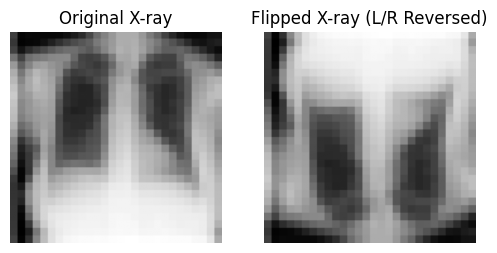

In [3]:
# Left/right flip all images in the numpy array along the horizontal axis (axis 2)
flipped_xray_array = np.fliplr(xray_array)

# Quick visualization of a side-by-side comparison for the first X-ray
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(xray_array[0], cmap='gray')
axes[0].set_title("Original X-ray")
axes[0].axis('off')

axes[1].imshow(flipped_xray_array[0], cmap='gray')
axes[1].set_title("Flipped X-ray (L/R Reversed)")
axes[1].axis('off')
plt.show()

In [4]:
# Install libraries to create plot of Jane Eyre book

import requests
from bs4 import BeautifulSoup
import re
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Download VADER lexicon for sentiment analysis
nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [5]:
import requests
from bs4 import BeautifulSoup
import re
import pandas as pd
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download('vader_lexicon')

# Download Jane Eyre HTML
url = "https://www.gutenberg.org/files/1260/1260-h/1260-h.htm"
response = requests.get(url)
response.encoding = 'utf-8'
soup = BeautifulSoup(response.text, 'html.parser')

# Extract chapters by looking at HTML elements (headings and paragraphs)
elements = soup.find_all(['h2', 'h3', 'h4', 'p'])

chapters = []
chap_title = None
chap_text = []

for tag in elements:
    text = tag.get_text().strip()
    # Check if the text starts with "CHAPTER" followed by a number/Roman numeral
    if re.match(r'^CHAPTER\s+[0-9IVXLCDM]+', text, re.IGNORECASE):
        if chap_title:
            chapters.append((chap_title, "\n".join(chap_text)))
        chap_title = text
        chap_text = []
    elif chap_title:
        chap_text.append(text)

# Append the final chapter
if chap_title:
    chapters.append((chap_title, "\n".join(chap_text)))

print(f"Total chapters found: {len(chapters)}")

# Calculate sentiment for each chapter
sia = SentimentIntensityAnalyzer()
chapter_sentiments = []

for title, content in chapters:
    score = sia.polarity_scores(content)
    chapter_sentiments.append({
        'Chapter': title,
        'Compound_Sentiment': score['compound']
    })

df_sentiment = pd.DataFrame(chapter_sentiments)
display(df_sentiment.head(10))

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Total chapters found: 38


,Chapter,Compound_Sentiment
0,CHAPTER I,-0.9658
1,CHAPTER II,-0.9998
2,CHAPTER III,0.7395
3,CHAPTER IV,0.9992
4,CHAPTER V,0.9990
5,CHAPTER VI,-0.9932
6,CHAPTER VII,-0.9874
7,CHAPTER VIII,0.9984
8,CHAPTER IX,0.9996
9,CHAPTER X,0.9998


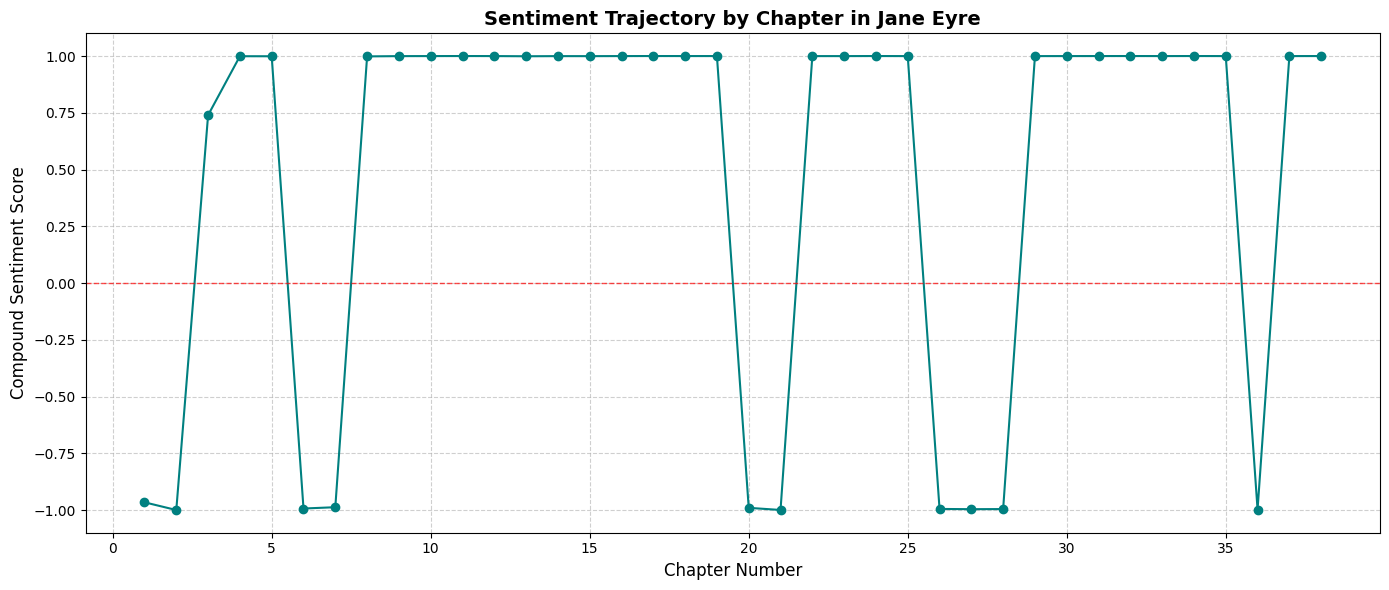

In [6]:
plt.figure(figsize=(14, 6))
plt.plot(range(1, len(df_sentiment) + 1), df_sentiment['Compound_Sentiment'], marker='o', linestyle='-', color='teal')
plt.title("Sentiment Trajectory by Chapter in Jane Eyre", fontsize=14, fontweight='bold')
plt.xlabel("Chapter Number", fontsize=12)
plt.ylabel("Compound Sentiment Score", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.axhline(0, color='red', linestyle='--', linewidth=1, alpha=0.7)
plt.tight_layout()
plt.show()